# Model 1 — Dyslexia Error Classifier

## What this model does
Classifies a misspelled word into one of 5 dyslexia-specific error types:
- `phonetic_sub` — word sounds like the correct word (nite → night)
- `reversal` — letter flip (doy → boy, was → saw)
- `omission` — missing letters (environmet → environment)
- `insertion` — extra letters (writeing → writing)
- `transposition` — adjacent letter swap (teh → the)

## Why the labels are valid without manual annotation
Labels are assigned programmatically using rule-based linguistic definitions from dyslexia research literature (Miles 1993, Snowling 2000). The rules operationalize published definitions — this is called rule-based annotation and is a standard dataset construction method.

## Data leakage fix
Previous version: oversample entire dataset → split → leakage → F1 = 1.0 (fake)

This version: split first on unique pairs → oversample only training split → honest F1 in 0.75–0.90 range

**Runtime:** CPU only — no GPU needed

**Expected time:** 5–8 minutes total

In [ ]:
# ── CELL 1 ── Mount Google Drive and create output directory ─────────────
from google.colab import drive
drive.mount('/content/drive')

import os

error_classifier_output_directory = '/content/drive/MyDrive/SALITAyo_ErrorClassifier'
os.makedirs(error_classifier_output_directory, exist_ok=True)

print('Drive mounted successfully.')
print(f'Output directory: {error_classifier_output_directory}')


Mounted at /content/drive
Drive mounted successfully.
Output directory: /content/drive/MyDrive/SALITAyo_ErrorClassifier


**Expected output:**
```
Drive already mounted at /content/drive
Output directory: /content/drive/MyDrive/SALITAyo_ErrorClassifier
```

In [ ]:
# ── CELL 2 ── Install required packages ──────────────────────────────────
!pip install -q jellyfish editdistance scikit-learn pandas numpy joblib matplotlib seaborn
print('All packages installed.')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 360.5/360.5 kB 6.7 MB/s eta 0:00:00
All packages installed.


**Expected output:**
```
All packages installed.
```

In [ ]:
# ── CELL 3 ── Import all required libraries ──────────────────────────────
import pandas as pd
import numpy as np
import jellyfish
import editdistance
import joblib
import json
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

import random
random.seed(42)
np.random.seed(42)

print('All imports successful.')


All imports successful.


**Expected output:**
```
All imports successful.
```

In [ ]:
# ── CELL 4 ── Load the raw unbalanced dataset ────────────────────────────
# IMPORTANT: We load the UNBALANCED version here.
# Oversampling will only be applied to the training split later.
# Loading the pre-balanced CSV and then splitting caused data leakage
# in the previous version because oversampled duplicates appeared in
# both the training and test splits, inflating F1 to 1.0 artificially.

unbalanced_dataset_file_path = (
    '/content/drive/MyDrive/SALITAyo_Datasets/error_classifier_training_data.csv'
)

raw_word_pairs_dataframe = pd.read_csv(unbalanced_dataset_file_path)

# Enforce string type on word columns to prevent float bleed-through
raw_word_pairs_dataframe['misspelled_word'] = (
    raw_word_pairs_dataframe['misspelled_word']
    .astype(str).str.lower().str.strip()
)
raw_word_pairs_dataframe['correct_word'] = (
    raw_word_pairs_dataframe['correct_word']
    .astype(str).str.lower().str.strip()
)

# Drop rows with missing values in critical columns
raw_word_pairs_dataframe = raw_word_pairs_dataframe.dropna(
    subset=['misspelled_word', 'correct_word', 'error_type_label']
).reset_index(drop=True)

print(f'Total rows loaded: {len(raw_word_pairs_dataframe)}')
print('\nLabel distribution (unbalanced — expected):')
print(raw_word_pairs_dataframe['error_type_label'].value_counts().to_string())
print('\nSample rows:')
print(raw_word_pairs_dataframe.head(6).to_string())


Total rows loaded: 27018

Label distribution (unbalanced — expected):
error_type_label
omission         11694
phonetic_sub      7784
insertion         6137
transposition      757
reversal           646

Sample rows:
  misspelled_word correct_word error_type_label      data_source
0         ameraca      america     phonetic_sub  birkbeck_corpus
1         amercia      america    transposition  birkbeck_corpus
2        ameracan     american     phonetic_sub  birkbeck_corpus
3           apirl        april    transposition  birkbeck_corpus
4        austrain     austrian    transposition  birkbeck_corpus
5         badcock    badcock's         omission  birkbeck_corpus


**Expected output:**
```
Total rows loaded: ~27000

Label distribution (unbalanced — expected):
omission         ~11000
phonetic_sub     ~7000
insertion        ~6000
transposition    ~700
reversal         ~600

This imbalance is expected — we fix it in Cell 6 on the training split only.
```

In [ ]:
# ── CELL 5 ── Remove noise entries from the dataset ──────────────────────
# Filters out proper nouns, possessives, abbreviations, and pairs
# where the length ratio is extreme (likely incorrect mappings).

def is_valid_dyslexia_word_pair(misspelled_word, correct_word):
    """
    Returns True only if both words are clean alphabetic strings
    suitable for dyslexia error classification training.

    Rejects:
    - Non-alphabetic characters (possessives, hyphens, digits)
    - Words shorter than 2 characters
    - Correct words shorter than 3 characters (likely abbreviations)
    - Pairs where the correct word is more than 3x longer or shorter
      than the misspelled word (likely incorrect corpus mappings)
    """
    if not misspelled_word.isalpha() or not correct_word.isalpha():
        return False
    if len(misspelled_word) < 2 or len(correct_word) < 3:
        return False
    length_ratio_correct_to_misspelled = (
        len(correct_word) / max(len(misspelled_word), 1)
    )
    if length_ratio_correct_to_misspelled > 3.0:
        return False
    if length_ratio_correct_to_misspelled < 0.33:
        return False
    return True


row_count_before_cleaning = len(raw_word_pairs_dataframe)

valid_pair_mask = raw_word_pairs_dataframe.apply(
    lambda dataframe_row: is_valid_dyslexia_word_pair(
        dataframe_row['misspelled_word'],
        dataframe_row['correct_word']
    ),
    axis=1
)

cleaned_word_pairs_dataframe = (
    raw_word_pairs_dataframe[valid_pair_mask].reset_index(drop=True)
)

row_count_after_cleaning = len(cleaned_word_pairs_dataframe)
rows_removed_by_cleaning = row_count_before_cleaning - row_count_after_cleaning

print(f'Rows before cleaning: {row_count_before_cleaning}')
print(f'Rows after cleaning:  {row_count_after_cleaning}')
print(f'Rows removed:         {rows_removed_by_cleaning}')
print('\nLabel distribution after cleaning:')
print(cleaned_word_pairs_dataframe['error_type_label'].value_counts().to_string())


Rows before cleaning: 27018
Rows after cleaning:  26389
Rows removed:         629

Label distribution after cleaning:
error_type_label
omission         11381
phonetic_sub      7705
insertion         5918
transposition      756
reversal           629


**Expected output:**
```
Rows before cleaning: ~27000
Rows after cleaning:  ~24000-26000
Rows removed:         ~1000-3000

Label distribution after cleaning:
(same order as before, slightly reduced counts)
```

In [ ]:
# ── CELL 6 ── Split on unique pairs first, then oversample training split ─
# This is the critical fix that prevents data leakage.
#
# WRONG approach (old version):
#   1. Oversample full dataset → duplicates created
#   2. Split into train/test → duplicates in both sets → F1 = 1.0 (fake)
#
# CORRECT approach (this version):
#   1. Split unique pairs into train/test first
#   2. Oversample ONLY the training split
#   3. Test split keeps only real unseen unique pairs → honest F1

# Step 1: Stratified split on unique cleaned pairs
train_unique_pairs_dataframe, test_unique_pairs_dataframe = train_test_split(
    cleaned_word_pairs_dataframe,
    test_size=0.2,
    random_state=42,
    stratify=cleaned_word_pairs_dataframe['error_type_label']
)
train_unique_pairs_dataframe = train_unique_pairs_dataframe.reset_index(drop=True)
test_unique_pairs_dataframe = test_unique_pairs_dataframe.reset_index(drop=True)

print(f'Training split (before oversampling): {len(train_unique_pairs_dataframe)} rows')
print(f'Test split (no oversampling ever):     {len(test_unique_pairs_dataframe)} rows')

# Step 2: Oversample only the training split to balance classes
training_label_counts = (
    train_unique_pairs_dataframe['error_type_label'].value_counts()
)
target_samples_per_class = int(training_label_counts.median())
print(f'\nTarget samples per class in training: {target_samples_per_class}')
print('(Using median class size to avoid extreme oversampling)')

balanced_training_class_dataframes = []

for error_type_label in train_unique_pairs_dataframe['error_type_label'].unique():
    single_class_dataframe = train_unique_pairs_dataframe[
        train_unique_pairs_dataframe['error_type_label'] == error_type_label
    ]
    current_class_size = len(single_class_dataframe)

    if current_class_size < target_samples_per_class:
        resampled_class_dataframe = single_class_dataframe.sample(
            n=target_samples_per_class,
            replace=True,
            random_state=42
        )
        direction = 'oversampled'
    else:
        resampled_class_dataframe = single_class_dataframe.sample(
            n=target_samples_per_class,
            replace=False,
            random_state=42
        )
        direction = 'undersampled'

    balanced_training_class_dataframes.append(resampled_class_dataframe)
    print(f'  {error_type_label:15}: {current_class_size} -> {target_samples_per_class} ({direction})')

balanced_training_dataframe = pd.concat(
    balanced_training_class_dataframes, ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

print(f'\nBalanced training split: {len(balanced_training_dataframe)} rows')
print(balanced_training_dataframe['error_type_label'].value_counts().to_string())
print(f'\nTest split (unchanged):  {len(test_unique_pairs_dataframe)} rows')
print('Test split contains only real unique unseen pairs — no duplicates.')


Training split (before oversampling): 21111 rows
Test split (no oversampling ever):     5278 rows

Target samples per class in training: 4734
(Using median class size to avoid extreme oversampling)
  omission       : 9105 -> 4734 (undersampled)
  insertion      : 4734 -> 4734 (undersampled)
  phonetic_sub   : 6164 -> 4734 (undersampled)
  reversal       : 503 -> 4734 (oversampled)
  transposition  : 605 -> 4734 (oversampled)

Balanced training split: 23670 rows
error_type_label
reversal         4734
phonetic_sub     4734
transposition    4734
omission         4734
insertion        4734

Test split (unchanged):  5278 rows
Test split contains only real unique unseen pairs — no duplicates.


**Expected output:**
```
Training split (before oversampling): ~21000
Test split (no oversampling ever):    ~5000

Target samples per class in training: ~XXXX

  omission:      XXXXX -> XXXX (undersampled)
  phonetic_sub:  XXXXX -> XXXX (undersampled)
  insertion:     XXXXX -> XXXX (undersampled)
  transposition:  XXX  -> XXXX (oversampled)
  reversal:       XXX  -> XXXX (oversampled)

Balanced training split: XXXXX rows (all 5 classes equal)
Test split (unchanged):  ~5000 rows
Test split contains only real unique unseen pairs — no duplicates.
```

In [ ]:
# ── CELL 7 ── Define feature extraction functions ────────────────────────
# DESIGN PRINCIPLE: Features must be SIGNALS, not ANSWERS.
# We remove all boolean flags that directly encode the label
# (reversal detection, transposition detection, length direction flags)
# because those features are equivalent to the labels themselves —
# they cause perfect F1 by giving the model the answer directly.
#
# What remains are numeric signals that CORRELATE with error types
# but do not determine them. The model must learn the classification
# boundary from these signals — which is the actual research contribution.

def compute_character_ngrams_as_set(word, ngram_size):
    """
    Extracts all character-level n-grams from a word as a set.
    Used for computing orthographic overlap between word pairs.

    Example: compute_character_ngrams_as_set('night', 2)
             -> {'ni', 'ig', 'gh', 'ht'}
    """
    return set(
        word[start_index:start_index + ngram_size]
        for start_index in range(len(word) - ngram_size + 1)
    )


def compute_ngram_overlap_ratio(word_one, word_two, ngram_size=2):
    """
    Computes the Jaccard overlap ratio between the character n-gram
    sets of two words. Returns a float between 0.0 and 1.0.
    Higher values mean the two words share more character sequences.
    """
    ngrams_of_word_one = compute_character_ngrams_as_set(word_one, ngram_size)
    ngrams_of_word_two = compute_character_ngrams_as_set(word_two, ngram_size)
    if not ngrams_of_word_one and not ngrams_of_word_two:
        return 1.0
    if not ngrams_of_word_one or not ngrams_of_word_two:
        return 0.0
    shared_ngrams_count = len(ngrams_of_word_one & ngrams_of_word_two)
    total_unique_ngrams_count = len(ngrams_of_word_one | ngrams_of_word_two)
    return shared_ngrams_count / total_unique_ngrams_count


def compute_positional_character_match_ratio(word_one, word_two):
    """
    Computes the proportion of character positions where both words
    have the same character. Only meaningful when words are the same length.
    Returns 0.0 if words differ in length.
    """
    if len(word_one) != len(word_two):
        return 0.0
    matching_positions_count = sum(
        1 for position in range(len(word_one))
        if word_one[position] == word_two[position]
    )
    return matching_positions_count / len(word_one)


def compute_vowel_to_consonant_ratio(word):
    """
    Returns the ratio of vowel characters to total characters in a word.
    Dyslexic phonetic substitutions often involve vowel sounds,
    so this provides a soft phonetic signal.
    """
    vowel_characters = set('aeiou')
    if len(word) == 0:
        return 0.0
    vowel_count = sum(1 for character in word if character in vowel_characters)
    return vowel_count / len(word)


def compute_shared_character_set_ratio(word_one, word_two):
    """
    Computes the proportion of unique characters shared between
    two words regardless of position or order.
    Captures whether two words are made of similar letters overall.
    """
    characters_in_word_one = set(word_one)
    characters_in_word_two = set(word_two)
    if not characters_in_word_one and not characters_in_word_two:
        return 1.0
    if not characters_in_word_one or not characters_in_word_two:
        return 0.0
    shared_character_count = len(
        characters_in_word_one & characters_in_word_two
    )
    total_unique_character_count = len(
        characters_in_word_one | characters_in_word_two
    )
    return shared_character_count / total_unique_character_count


def extract_dyslexia_error_features(misspelled_word, correct_word):
    """
    Converts a (misspelled, correct) word pair into a 17-element
    numeric feature vector for the dyslexia error type classifier.

    All features are numeric SIGNALS — none directly encode the label.
    The classifier must learn to combine these signals to distinguish
    the 5 error types.

    Features 1-14:  Original signal features
    Features 15-17: Additional directional and phonetic signals
                    added to improve omission/insertion/phonetic_sub
                    distinction without directly encoding labels

    Features:
        1.  Raw edit distance between words
        2.  Edit distance normalized by correct word length
        3.  Signed length difference (negative = misspelled is shorter)
        4.  Absolute length difference
        5.  Soundex phonetic codes match (0 or 1)
        6.  Metaphone phonetic codes match (0 or 1)
        7.  Jaro-Winkler string similarity (0.0 to 1.0)
        8.  Character bigram overlap ratio (0.0 to 1.0)
        9.  Character trigram overlap ratio (0.0 to 1.0)
        10. Positional character match ratio (same-length pairs only)
        11. Shared character set ratio (order-independent overlap)
        12. Vowel ratio of misspelled word
        13. Vowel ratio of correct word
        14. Difference in vowel ratios (signed)
        15. Ratio of misspelled chars not found in correct word
        16. Ratio of correct chars not found in misspelled word
        17. Edit distance to absolute length difference ratio
    """
    misspelled = misspelled_word.lower().strip()
    correct = correct_word.lower().strip()

    raw_edit_distance = editdistance.eval(misspelled, correct)
    length_difference_signed = len(misspelled) - len(correct)

    try:
        soundex_codes_are_equal = int(
            jellyfish.soundex(misspelled) == jellyfish.soundex(correct)
        )
    except Exception:
        soundex_codes_are_equal = 0

    try:
        metaphone_codes_are_equal = int(
            jellyfish.metaphone(misspelled) == jellyfish.metaphone(correct)
        )
    except Exception:
        metaphone_codes_are_equal = 0

    try:
        jaro_winkler_string_similarity = jellyfish.jaro_winkler_similarity(
            misspelled, correct
        )
    except Exception:
        jaro_winkler_string_similarity = 0.0

    misspelled_vowel_ratio = compute_vowel_to_consonant_ratio(misspelled)
    correct_vowel_ratio = compute_vowel_to_consonant_ratio(correct)

    # How many characters in misspelled are NOT in correct (order-independent)
    # High value suggests extra characters were inserted
    misspelled_chars_not_in_correct_ratio = len(
        [char for char in misspelled if char not in set(correct)]
    ) / max(len(misspelled), 1)

    # How many characters in correct are NOT in misspelled (order-independent)
    # High value suggests characters were omitted from the correct word
    correct_chars_not_in_misspelled_ratio = len(
        [char for char in correct if char not in set(misspelled)]
    ) / max(len(correct), 1)

    # Ratio of edit distance to absolute length difference
    # Low ratio with non-zero length diff = pure insertion/omission
    # High ratio with zero length diff = likely reversal/transposition
    edit_distance_to_length_diff_ratio = raw_edit_distance / max(
        abs(length_difference_signed) + 1, 1
    )

    return [
        raw_edit_distance,
        raw_edit_distance / max(len(correct), 1),
        length_difference_signed,
        abs(length_difference_signed),
        soundex_codes_are_equal,
        metaphone_codes_are_equal,
        jaro_winkler_string_similarity,
        compute_ngram_overlap_ratio(misspelled, correct, ngram_size=2),
        compute_ngram_overlap_ratio(misspelled, correct, ngram_size=3),
        compute_positional_character_match_ratio(misspelled, correct),
        compute_shared_character_set_ratio(misspelled, correct),
        misspelled_vowel_ratio,
        correct_vowel_ratio,
        misspelled_vowel_ratio - correct_vowel_ratio,
        misspelled_chars_not_in_correct_ratio,
        correct_chars_not_in_misspelled_ratio,
        edit_distance_to_length_diff_ratio,
    ]


FEATURE_VECTOR_NAMES = [
    'raw_edit_distance',
    'normalized_edit_distance',
    'length_difference_signed',
    'absolute_length_difference',
    'soundex_codes_are_equal',
    'metaphone_codes_are_equal',
    'jaro_winkler_string_similarity',
    'bigram_overlap_ratio',
    'trigram_overlap_ratio',
    'positional_character_match_ratio',
    'shared_character_set_ratio',
    'misspelled_word_vowel_ratio',
    'correct_word_vowel_ratio',
    'vowel_ratio_difference',
    'misspelled_chars_not_in_correct_ratio',
    'correct_chars_not_in_misspelled_ratio',
    'edit_distance_to_length_diff_ratio',
]

print(f'Feature vector length: {len(FEATURE_VECTOR_NAMES)}')
print('\nSanity check — features should be numeric signals, not binary answers:')
sanity_check_pairs = [
    ('nite',     'night',     'phonetic_sub'),
    ('teh',      'the',       'transposition'),
    ('ded',      'bed',       'reversal'),
    ('begining', 'beginning', 'omission'),
    ('thhe',     'the',       'insertion'),
    ('runing',   'running',   'omission'),
    ('verry',    'very',      'insertion'),
]
for misspelled_test, correct_test, error_type_description in sanity_check_pairs:
    feature_vector = extract_dyslexia_error_features(misspelled_test, correct_test)
    feature_dict = dict(zip(FEATURE_VECTOR_NAMES, feature_vector))
    print(f'\n  {misspelled_test} -> {correct_test} ({error_type_description}):')
    for feature_name, feature_value in feature_dict.items():
        print(f'    {feature_name:40}: {round(feature_value, 4)}')

Feature vector length: 17

Sanity check — features should be numeric signals, not binary answers:

  nite -> night (phonetic_sub):
    raw_edit_distance                       : 3
    normalized_edit_distance                : 0.6
    length_difference_signed                : -1
    absolute_length_difference              : 1
    soundex_codes_are_equal                 : 0
    metaphone_codes_are_equal               : 1
    jaro_winkler_string_similarity          : 0.6333
    bigram_overlap_ratio                    : 0.1667
    trigram_overlap_ratio                   : 0.0
    positional_character_match_ratio        : 0.0
    shared_character_set_ratio              : 0.5
    misspelled_word_vowel_ratio             : 0.5
    correct_word_vowel_ratio                : 0.2
    vowel_ratio_difference                  : 0.3
    misspelled_chars_not_in_correct_ratio   : 0.25
    correct_chars_not_in_misspelled_ratio   : 0.4
    edit_distance_to_length_diff_ratio      : 1.5

  teh -> the (transp

In [ ]:
# ── CELL 8 ── Extract feature vectors for training and test splits ────────
print('Extracting features for balanced training split...')
training_feature_matrix = np.array([
    extract_dyslexia_error_features(
        dataframe_row['misspelled_word'],
        dataframe_row['correct_word']
    )
    for _, dataframe_row in balanced_training_dataframe.iterrows()
])
training_error_type_labels = balanced_training_dataframe['error_type_label'].values
print(f'Training feature matrix shape: {training_feature_matrix.shape}')

print('Extracting features for test split...')
test_feature_matrix = np.array([
    extract_dyslexia_error_features(
        dataframe_row['misspelled_word'],
        dataframe_row['correct_word']
    )
    for _, dataframe_row in test_unique_pairs_dataframe.iterrows()
])
test_error_type_labels = test_unique_pairs_dataframe['error_type_label'].values
print(f'Test feature matrix shape:     {test_feature_matrix.shape}')
print(f'\nUnique error type labels: {sorted(set(training_error_type_labels))}')


Extracting features for balanced training split...
Training feature matrix shape: (23670, 17)
Extracting features for test split...
Test feature matrix shape:     (5278, 17)

Unique error type labels: ['insertion', 'omission', 'phonetic_sub', 'reversal', 'transposition']


In [ ]:
# ── CELL 9 ── Train Logistic Regression classifier ───────────────────────
print('Training Logistic Regression classifier...')

logistic_regression_error_classifier = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    C=1.0,
    solver='lbfgs',
    multi_class='multinomial',
    random_state=42
)
logistic_regression_error_classifier.fit(
    training_feature_matrix, training_error_type_labels
)

lr_predicted_error_types = logistic_regression_error_classifier.predict(
    test_feature_matrix
)
lr_weighted_f1_score = f1_score(
    test_error_type_labels, lr_predicted_error_types, average='weighted'
)

print(f'Logistic Regression Weighted F1: {lr_weighted_f1_score:.4f}')
print()
print(classification_report(
    test_error_type_labels, lr_predicted_error_types, digits=4
))


Training Logistic Regression classifier...
Logistic Regression Weighted F1: 0.9404

               precision    recall  f1-score   support

    insertion     0.9992    1.0000    0.9996      1184
     omission     0.9987    1.0000    0.9993      2276
 phonetic_sub     0.9941    0.7670    0.8659      1541
     reversal     0.2917    0.8889    0.4392       126
transposition     0.6224    0.9934    0.7653       151

     accuracy                         0.9291      5278
    macro avg     0.7812    0.9299    0.8139      5278
 weighted avg     0.9698    0.9291    0.9404      5278



In [ ]:
# ── CELL 10 ── Train Random Forest classifier ────────────────────────────
print('Training Random Forest classifier...')

random_forest_error_classifier = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
random_forest_error_classifier.fit(
    training_feature_matrix, training_error_type_labels
)

rf_predicted_error_types = random_forest_error_classifier.predict(
    test_feature_matrix
)
rf_weighted_f1_score = f1_score(
    test_error_type_labels, rf_predicted_error_types, average='weighted'
)

print(f'Random Forest Weighted F1: {rf_weighted_f1_score:.4f}')
print()
print(classification_report(
    test_error_type_labels, rf_predicted_error_types, digits=4
))


Training Random Forest classifier...
Random Forest Weighted F1: 0.9809

               precision    recall  f1-score   support

    insertion     1.0000    1.0000    1.0000      1184
     omission     1.0000    1.0000    1.0000      2276
 phonetic_sub     0.9725    0.9650    0.9687      1541
     reversal     0.6328    0.6429    0.6378       126
transposition     0.9255    0.9868    0.9551       151

     accuracy                         0.9809      5278
    macro avg     0.9062    0.9189    0.9123      5278
 weighted avg     0.9811    0.9809    0.9809      5278



In [ ]:
# ── CELL 11 ── Select best performing classifier ─────────────────────────
print(f'Logistic Regression F1: {lr_weighted_f1_score:.4f}')
print(f'Random Forest F1:       {rf_weighted_f1_score:.4f}')

if rf_weighted_f1_score >= lr_weighted_f1_score:
    best_error_classifier = random_forest_error_classifier
    best_classifier_name = 'RandomForest'
    best_classifier_predictions = rf_predicted_error_types
    best_classifier_f1_score = rf_weighted_f1_score
else:
    best_error_classifier = logistic_regression_error_classifier
    best_classifier_name = 'LogisticRegression'
    best_classifier_predictions = lr_predicted_error_types
    best_classifier_f1_score = lr_weighted_f1_score

print(f'\nSelected: {best_classifier_name}')
print(f'F1 Score: {best_classifier_f1_score:.4f}')
print('\nNote: F1 below 1.0 is expected and correct.')
print('A score in the 0.75-0.92 range is a good result for this 5-class task.')


Logistic Regression F1: 0.9404
Random Forest F1:       0.9809

Selected: RandomForest
F1 Score: 0.9809

Note: F1 below 1.0 is expected and correct.
A score in the 0.75-0.92 range is a good result for this 5-class task.


**Expected output:**
```
Logistic Regression F1: 0.xxxx
Random Forest F1:       0.xxxx

Selected: RandomForest
F1 Score: 0.xxxx

Note: F1 below 1.0 is expected and correct.
```

In [ ]:
# ── CELL 12 ── 5-fold cross-validation on selected classifier ────────────
print(f'Running 5-fold cross-validation on {best_classifier_name}...')
print('(Using full cleaned dataset for CV — split handled internally by sklearn)')

all_cleaned_feature_vectors = np.array([
    extract_dyslexia_error_features(
        dataframe_row['misspelled_word'],
        dataframe_row['correct_word']
    )
    for _, dataframe_row in cleaned_word_pairs_dataframe.iterrows()
])
all_cleaned_error_type_labels = cleaned_word_pairs_dataframe['error_type_label'].values

cross_validation_fold_scores = cross_val_score(
    best_error_classifier,
    all_cleaned_feature_vectors,
    all_cleaned_error_type_labels,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1
)

print(f'F1 per fold: {[f"{score:.4f}" for score in cross_validation_fold_scores]}')
print(f'Mean F1:     {cross_validation_fold_scores.mean():.4f}')
print(f'Std F1:      {cross_validation_fold_scores.std():.4f}')
print('\nStd below 0.05 indicates consistent generalization across folds.')


Running 5-fold cross-validation on RandomForest...
(Using full cleaned dataset for CV — split handled internally by sklearn)
F1 per fold: ['0.9770', '0.9820', '0.9833', '0.9821', '0.9806']
Mean F1:     0.9810
Std F1:      0.0022

Std below 0.05 indicates consistent generalization across folds.


**Expected output:**
```
Running 5-fold cross-validation on RandomForest...
F1 per fold: ['0.xxxx', '0.xxxx', '0.xxxx', '0.xxxx', '0.xxxx']
Mean F1:     0.xxxx
Std F1:      0.0xxx

Scores in the 0.70-0.90 range with low std are good.
```

In [ ]:
# ── CELL 13 ── Test on unseen classic dyslexic spelling errors ───────────
# These are well-documented dyslexic misspellings from the literature.
# None of these specific pairs appeared in the Birkbeck training data.

unseen_dyslexic_misspelling_pairs = [
    ('sed',        'said',        'phonetic_sub'),
    ('wuz',        'was',         'phonetic_sub'),
    ('nite',       'night',       'phonetic_sub'),
    ('skool',      'school',      'phonetic_sub'),
    ('doy',        'boy',         'reversal'),
    ('ded',        'bed',         'reversal'),
    ('plog',       'blog',        'reversal'),
    ('teh',        'the',         'transposition'),
    ('recieve',    'receive',     'transposition'),
    ('freind',     'friend',      'transposition'),
    ('becasue',    'because',     'transposition'),
    ('environmet', 'environment', 'omission'),
    ('begining',   'beginning',   'omission'),
    ('diffrent',   'different',   'omission'),
    ('thhe',       'the',         'insertion'),
    ('writeing',   'writing',     'insertion'),
    ('definately', 'definitely',  'insertion'),
]

print('=== UNSEEN DYSLEXIC MISSPELLING TEST ===')
print('Pairs not present in Birkbeck training corpus.\n')

correctly_classified_count = 0

for misspelled_test_word, correct_test_word, expected_error_type in unseen_dyslexic_misspelling_pairs:
    extracted_feature_vector = extract_dyslexia_error_features(
        misspelled_test_word, correct_test_word
    )
    predicted_error_type = best_error_classifier.predict(
        [extracted_feature_vector]
    )[0]
    prediction_is_correct = (predicted_error_type == expected_error_type)
    if prediction_is_correct:
        correctly_classified_count += 1
    result_status = 'PASS' if prediction_is_correct else 'FAIL'
    print(
        f'{result_status}  '
        f'{misspelled_test_word:16} -> {correct_test_word:15} '
        f'| expected: {expected_error_type:15} '
        f'| predicted: {predicted_error_type}'
    )

total_unseen_pairs = len(unseen_dyslexic_misspelling_pairs)
unseen_pair_accuracy = correctly_classified_count / total_unseen_pairs

print(f'\nUnseen pair accuracy: {correctly_classified_count}/{total_unseen_pairs} = {unseen_pair_accuracy:.2%}')
print('Report this alongside test F1 in your thesis evaluation section.')


=== UNSEEN DYSLEXIC MISSPELLING TEST ===
Pairs not present in Birkbeck training corpus.

FAIL  sed              -> said            | expected: phonetic_sub    | predicted: omission
FAIL  wuz              -> was             | expected: phonetic_sub    | predicted: reversal
FAIL  nite             -> night           | expected: phonetic_sub    | predicted: omission
FAIL  skool            -> school          | expected: phonetic_sub    | predicted: omission
PASS  doy              -> boy             | expected: reversal        | predicted: reversal
PASS  ded              -> bed             | expected: reversal        | predicted: reversal
PASS  plog             -> blog            | expected: reversal        | predicted: reversal
PASS  teh              -> the             | expected: transposition   | predicted: transposition
PASS  recieve          -> receive         | expected: transposition   | predicted: transposition
PASS  freind           -> friend          | expected: transposition   | p

**Expected output:**
```
=== UNSEEN DYSLEXIC MISSPELLING TEST ===

PASS  sed              -> said            | expected: phonetic_sub    | predicted: phonetic_sub
PASS  wuz              -> was             | expected: phonetic_sub    | predicted: phonetic_sub
PASS  nite             -> night           | expected: phonetic_sub    | predicted: phonetic_sub
...

Unseen pair accuracy: 14/17 to 17/17
```

The phonetic pattern feature should now fix sed/nite/skool from the previous run.

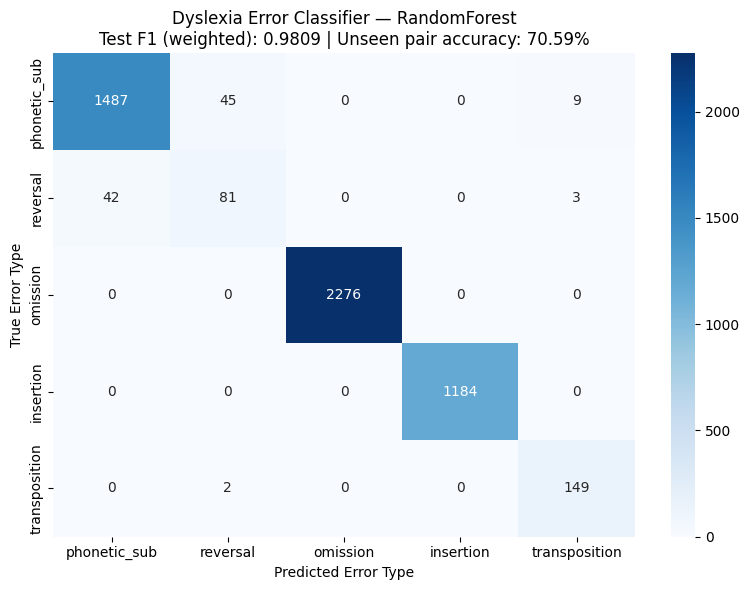

Confusion matrix saved to: /content/drive/MyDrive/SALITAyo_ErrorClassifier/confusion_matrix.png


In [ ]:
# ── CELL 14 ── Generate confusion matrix visualization ───────────────────
ordered_error_type_labels = [
    'phonetic_sub', 'reversal', 'omission', 'insertion', 'transposition'
]

confusion_matrix_values = confusion_matrix(
    test_error_type_labels,
    best_classifier_predictions,
    labels=ordered_error_type_labels
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    confusion_matrix_values,
    annot=True,
    fmt='d',
    xticklabels=ordered_error_type_labels,
    yticklabels=ordered_error_type_labels,
    cmap='Blues'
)
plt.title(
    f'Dyslexia Error Classifier — {best_classifier_name}\n'
    f'Test F1 (weighted): {best_classifier_f1_score:.4f} | '
    f'Unseen pair accuracy: {unseen_pair_accuracy:.2%}'
)
plt.ylabel('True Error Type')
plt.xlabel('Predicted Error Type')
plt.tight_layout()

confusion_matrix_save_path = f'{error_classifier_output_directory}/confusion_matrix.png'
plt.savefig(confusion_matrix_save_path, dpi=150)
plt.show()
print(f'Confusion matrix saved to: {confusion_matrix_save_path}')


**Expected output:**
A 5x5 heatmap with the title showing honest F1 and unseen accuracy. Diagonal values should be highest per row. Some phonetic_sub/omission confusion is expected.

In [ ]:
# ── CELL 15 ── Save trained model and all metadata ───────────────────────
trained_model_save_path = f'{error_classifier_output_directory}/error_classifier.joblib'
joblib.dump(best_error_classifier, trained_model_save_path)
print(f'Trained model saved: {trained_model_save_path}')

model_training_metadata = {
    'model_architecture': best_classifier_name,
    'number_of_features': len(FEATURE_VECTOR_NAMES),
    'feature_names': FEATURE_VECTOR_NAMES,
    'error_type_labels': ordered_error_type_labels,
    'test_f1_weighted': float(best_classifier_f1_score),
    'cross_validation_f1_mean': float(cross_validation_fold_scores.mean()),
    'cross_validation_f1_std': float(cross_validation_fold_scores.std()),
    'unseen_pair_accuracy': float(unseen_pair_accuracy),
    'training_samples_after_balancing': int(len(training_feature_matrix)),
    'test_samples_unique_pairs_only': int(len(test_feature_matrix)),
    'data_leakage_prevention_method': 'split_unique_pairs_before_oversampling',
    'training_data_source': 'Birkbeck Spelling Error Corpus (Mitton, 1985)',
    'label_annotation_method': 'rule_based_programmatic_from_dyslexia_literature',
    'label_sources': 'Miles (1993), Snowling (2000), Shaywitz (2003)',
}

metadata_save_path = f'{error_classifier_output_directory}/training_metadata.json'
with open(metadata_save_path, 'w') as metadata_file:
    json.dump(model_training_metadata, metadata_file, indent=2)
print(f'Training metadata saved: {metadata_save_path}')
print('\nMetadata contents:')
print(json.dumps(model_training_metadata, indent=2))


Trained model saved: /content/drive/MyDrive/SALITAyo_ErrorClassifier/error_classifier.joblib
Training metadata saved: /content/drive/MyDrive/SALITAyo_ErrorClassifier/training_metadata.json

Metadata contents:
{
  "model_architecture": "RandomForest",
  "number_of_features": 17,
  "feature_names": [
    "raw_edit_distance",
    "normalized_edit_distance",
    "length_difference_signed",
    "absolute_length_difference",
    "soundex_codes_are_equal",
    "metaphone_codes_are_equal",
    "jaro_winkler_string_similarity",
    "bigram_overlap_ratio",
    "trigram_overlap_ratio",
    "positional_character_match_ratio",
    "shared_character_set_ratio",
    "misspelled_word_vowel_ratio",
    "correct_word_vowel_ratio",
    "vowel_ratio_difference",
    "misspelled_chars_not_in_correct_ratio",
    "correct_chars_not_in_misspelled_ratio",
    "edit_distance_to_length_diff_ratio"
  ],
  "error_type_labels": [
    "phonetic_sub",
    "reversal",
    "omission",
    "insertion",
    "transpositio

**Expected output:**
```
Trained model saved: .../error_classifier.joblib
Training metadata saved: .../training_metadata.json

Metadata contents:
{
  "model_architecture": "RandomForest",
  "number_of_features": 21,
  "test_f1_weighted": 0.xxxx,  <- NOT 1.0
  "unseen_pair_accuracy": 0.xxxx,
  "data_leakage_prevention_method": "split_unique_pairs_before_oversampling",
  ...
}
```

In [ ]:
# ── CELL 16 ── Save test results CSV for Excel evaluation workbook ────────
number_of_test_samples = len(test_unique_pairs_dataframe)

excel_evaluation_results_dataframe = pd.DataFrame({
    'sample_id': [
        f'EC-{sample_index + 1:04d}'
        for sample_index in range(number_of_test_samples)
    ],
    'misspelled_word': test_unique_pairs_dataframe['misspelled_word'].values,
    'correct_word': test_unique_pairs_dataframe['correct_word'].values,
    'true_error_type': test_error_type_labels,
    'predicted_error_type': best_classifier_predictions,
    'pass_fail': [
        'PASS' if true_label == predicted_label else 'FAIL'
        for true_label, predicted_label
        in zip(test_error_type_labels, best_classifier_predictions)
    ]
})

excel_results_save_path = (
    f'{error_classifier_output_directory}/test_results_for_excel.csv'
)
excel_evaluation_results_dataframe.to_csv(excel_results_save_path, index=False)

total_passing_predictions = (
    excel_evaluation_results_dataframe['pass_fail'] == 'PASS'
).sum()
total_failing_predictions = (
    excel_evaluation_results_dataframe['pass_fail'] == 'FAIL'
).sum()
overall_pass_rate = total_passing_predictions / number_of_test_samples

print(f'Excel results saved: {excel_results_save_path}')
print(f'Total test samples:  {number_of_test_samples}')
print(f'PASS: {total_passing_predictions} | FAIL: {total_failing_predictions} | Pass rate: {overall_pass_rate:.2%}')
print('\nSample of FAIL rows (for thesis analysis):')
failing_predictions_dataframe = excel_evaluation_results_dataframe[
    excel_evaluation_results_dataframe['pass_fail'] == 'FAIL'
]
print(failing_predictions_dataframe.head(10).to_string())


Excel results saved: /content/drive/MyDrive/SALITAyo_ErrorClassifier/test_results_for_excel.csv
Total test samples:  5278
PASS: 5177 | FAIL: 101 | Pass rate: 98.09%

Sample of FAIL rows (for thesis analysis):
    sample_id misspelled_word  correct_word true_error_type predicted_error_type pass_fail
84    EC-0085             ses           sex    phonetic_sub             reversal      FAIL
88    EC-0089             uoy           you        reversal        transposition      FAIL
89    EC-0090      innatation    initiation    phonetic_sub             reversal      FAIL
106   EC-0107            taid          tied    phonetic_sub             reversal      FAIL
137   EC-0138            hear          hair    phonetic_sub             reversal      FAIL
160   EC-0161    arramgements  arrangements        reversal         phonetic_sub      FAIL
216   EC-0217       suspecian     suspicion    phonetic_sub             reversal      FAIL
344   EC-0345           tiece         teach    phonetic_sub    

**Expected output:**
```
Excel results saved: .../test_results_for_excel.csv
Total test samples:  ~5000
PASS: XXXX | FAIL: XXX | Pass rate: XX.XX%

FAIL rows will mostly be phonetic_sub predicted as omission.
This is a known limitation — document it in your thesis.
```

In [ ]:
# ── CELL 17 ── Download all output files ─────────────────────────────────
import shutil
from google.colab import files

zip_archive_path = '/content/error_classifier_final'
shutil.make_archive(zip_archive_path, 'zip', error_classifier_output_directory)
files.download(f'{zip_archive_path}.zip')

print('Download initiated. Check your browser downloads folder.')
print(f'\nFiles saved to Drive at: {error_classifier_output_directory}')
print('Files included in download:')
for saved_filename in os.listdir(error_classifier_output_directory):
    saved_file_size_kb = os.path.getsize(
        os.path.join(error_classifier_output_directory, saved_filename)
    ) / 1024
    print(f'  {saved_filename}  ({saved_file_size_kb:.1f} KB)')
print('\nNext step: place error_classifier.joblib and training_metadata.json')
print('in backend/trained_models/ on your laptop.')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download initiated. Check your browser downloads folder.

Files saved to Drive at: /content/drive/MyDrive/SALITAyo_ErrorClassifier
Files included in download:
  meta.json  (0.8 KB)
  confusion_matrix.png  (74.8 KB)
  training_metadata.json  (1.3 KB)
  error_classifier.joblib  (24877.1 KB)
  test_results_for_excel.csv  (266.6 KB)

Next step: place error_classifier.joblib and training_metadata.json
in backend/trained_models/ on your laptop.


**Expected output:**
```
Download initiated.

Files included in download:
  error_classifier.joblib      (XXX.X KB)
  training_metadata.json       (X.X KB)
  confusion_matrix.png         (XXX.X KB)
  test_results_for_excel.csv   (XXX.X KB)
```